# Pré-processamento — Base SportArena

Dataset: `packages/database/prisma/data/products.json`  
Alvo (análise / recomendações): `collection` (tipo de produto no catálogo)

Pipeline adaptado do notebook Heart Attack para a base de e-commerce esportivo:
limpeza do catálogo, engenharia de atributos úteis às sugestões
("se comprou X, pode gostar de Y") e exportação pronta para o seed do Prisma.

## Carregando os dados

In [1]:
import json
import re
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path('.').resolve()
PRODUCTS_PATH = ROOT / 'packages' / 'database' / 'prisma' / 'data' / 'products.json'
CATEGORIES_PATH = ROOT / 'packages' / 'database' / 'prisma' / 'data' / 'categories.json'
OUT_DIR = ROOT / 'packages' / 'database' / 'prisma' / 'data'

if not PRODUCTS_PATH.exists():
    raise FileNotFoundError(
        f"Nao encontrei {PRODUCTS_PATH}. "
        "Execute o notebook na raiz do repositorio SportArena."
    )

with PRODUCTS_PATH.open(encoding='utf-8') as f:
    products_raw = json.load(f)

df = pd.DataFrame(products_raw)
print(f'Base carregada: {df.shape[0]} produtos, {df.shape[1]} colunas')
print('Colunas:', list(df.columns))
df.head()

Base carregada: 546 produtos, 13 colunas
Colunas: ['name', 'brand', 'description', 'price', 'compareAt', 'size', 'color', 'sport', 'stock', 'imageUrl', 'category', 'active', 'slug']


,name,brand,description,price,compareAt,size,color,sport,stock,imageUrl,category,active,slug
0,Tênis Running Pro X,ArenaRun,Tênis de corrida com amortecimento responsivo ...,399.9,499.9,42,Preto/Verde,Corrida,25,https://images.unsplash.com/photo-1542291026-7...,Calçados,True,tenis-running-pro-x
1,Camisa Futebol Dry-Fit,KickSport,Camisa esportiva em tecido dry-fit que absorve...,129.9,NaN,M,Verde,Futebol,40,https://images.unsplash.com/photo-157656658802...,Camisetas,True,camisa-futebol-dry-fit
2,Bola Oficial Campo,GoalMax,"Bola de futebol tamanho oficial, costura térmi...",189.9,NaN,5,Branco,Futebol,15,https://images.unsplash.com/photo-161463253719...,Bolas,True,bola-oficial-campo
3,Garrafa Térmica 750ml,HydroFit,"Garrafa térmica em aço inox, mantém temperatur...",79.9,NaN,NaN,Azul,Geral,60,https://images.unsplash.com/photo-160214340715...,Acessórios,True,garrafa-termica-750ml
4,Halteres 5kg (par),IronGym,Par de halteres com revestimento emborrachado ...,149.9,NaN,5kg,Preto,Musculação,20,https://images.unsplash.com/photo-158345411055...,Equipamentos,True,halteres-5kg-par


## Pré-processamento: eliminação / seleção de atributos

Mantemos os campos usados pelo schema Prisma (`Product`) e derivamos
atributos auxiliares para análise e recomendações.

In [2]:
# Campos do catálogo (seed / API)
CAMPOS_CATALOGO = [
    'name', 'brand', 'description', 'price', 'compareAt',
    'size', 'color', 'sport', 'stock', 'imageUrl',
    'category', 'active', 'slug',
]

# Atributos numéricos para análise / normalização
ATRIBUTOS_NUM = ['price', 'compareAt', 'stock', 'desconto_pct']

# Alvo categórico alinhado às coleções do menu (apps/api/src/products/collections.ts)
ALVO = 'collection'

faltantes = [c for c in CAMPOS_CATALOGO if c not in df.columns]
if faltantes:
    raise ValueError(f'Colunas esperadas ausentes: {faltantes}')

df = df[CAMPOS_CATALOGO].copy()
print('Colunas do catálogo:', CAMPOS_CATALOGO)
print('Alvo de análise:', ALVO)
display(df.head(n=10))

Colunas do catálogo: ['name', 'brand', 'description', 'price', 'compareAt', 'size', 'color', 'sport', 'stock', 'imageUrl', 'category', 'active', 'slug']
Alvo de análise: collection


,name,brand,description,price,compareAt,size,color,sport,stock,imageUrl,category,active,slug
0,Tênis Running Pro X,ArenaRun,Tênis de corrida com amortecimento responsivo ...,399.9,499.9,42,Preto/Verde,Corrida,25,https://images.unsplash.com/photo-1542291026-7...,Calçados,True,tenis-running-pro-x
1,Camisa Futebol Dry-Fit,KickSport,Camisa esportiva em tecido dry-fit que absorve...,129.9,NaN,M,Verde,Futebol,40,https://images.unsplash.com/photo-157656658802...,Camisetas,True,camisa-futebol-dry-fit
2,Bola Oficial Campo,GoalMax,"Bola de futebol tamanho oficial, costura térmi...",189.9,NaN,5,Branco,Futebol,15,https://images.unsplash.com/photo-161463253719...,Bolas,True,bola-oficial-campo
3,Garrafa Térmica 750ml,HydroFit,"Garrafa térmica em aço inox, mantém temperatur...",79.9,NaN,NaN,Azul,Geral,60,https://images.unsplash.com/photo-160214340715...,Acessórios,True,garrafa-termica-750ml
4,Halteres 5kg (par),IronGym,Par de halteres com revestimento emborrachado ...,149.9,NaN,5kg,Preto,Musculação,20,https://images.unsplash.com/photo-158345411055...,Equipamentos,True,halteres-5kg-par
5,Shorts Training Flex,ArenaRun,"Shorts com elastano, bolso lateral e cordão aj...",99.9,NaN,G,Cinza,Treino,35,https://images.unsplash.com/photo-159119585382...,Camisetas,True,shorts-training-flex
6,Tênis Trail Grip Max,ArenaRun,"Solado com cravos para trilha, proteção no bic...",459.9,529.9,41,Cinza/Laranja,Corrida,18,https://images.unsplash.com/photo-160610755719...,Calçados,True,tenis-trail-grip-max
7,Tênis Basketball Elevate,JumpPro,Estabilidade lateral e amortecimento para pivô...,489.9,NaN,43,Branco/Preto,Basquete,14,https://images.unsplash.com/photo-159595065310...,Calçados,True,tenis-basketball-elevate
8,Camisa Running Breath,ArenaRun,Malha leve e respirável com proteção UV para c...,119.9,NaN,G,Azul,Corrida,32,https://images.unsplash.com/photo-152157216347...,Camisetas,True,camisa-running-breath
9,Regata Training Core,IronGym,"Regata anatômica para musculação e HIIT, tecid...",89.9,NaN,M,Preto,Musculação,45,https://images.unsplash.com/photo-150334221750...,Camisetas,True,regata-training-core


## Engenharia de atributos (gênero, coleção, desconto)

A base original concentra quase tudo em "Camisetas". Inferimos o tipo real
pelo nome/descrição — a mesma lógica das coleções da API.

In [3]:
def contem(texto: str, termos: list[str]) -> bool:
    t = (texto or '').lower()
    return any(term in t for term in termos)

TOP_TERMS = ['camiseta', 'camisa', 'camisola', 't-shirt', 'regata', 'polo', 'jersey']
KIDS_TERMS = ['infantil', 'júnior', 'junior', 'criança', 'crianca', 'rapaz', 'kids', 'bebê', 'menino', 'menina']
PANTS_TERMS = ['calça', 'calca', 'legging', 'jogger', 'tights']
SHORTS_TERMS = ['shorts', 'short ', 'bermuda', 'calções', 'calcoes', 'saia', 'macacão']
WARM_TERMS = ['moletom', 'moleton', 'moletinho', 'agasalho', 'blusa', 'sweat', 'hood', 'capuz', 'casaco', 'jaqueta', 'corta-vento', 'windrunner', 'suéter', 'sueter', 'fleece', 'colete', 'fato de treino']
TOPS_TERMS = ['sutiã', 'sutia', 'bralette', 'top ']
GEAR_TERMS = ['bucket', 'boné', 'bone ', 'chapéu', 'viseira', 'mochila', 'meias', 'bola', 'kettlebell']
SHOE_TERMS = ['tênis', 'tenis', 'chuteira', 'sapato']

def infer_genero(row) -> str:
    texto = f"{row.get('name', '')} {row.get('description', '')}".lower()
    if contem(texto, KIDS_TERMS):
        return 'infantil'
    if '(feminino)' in texto or ' mulher' in texto or texto.endswith('mulher'):
        return 'feminino'
    if '(masculino)' in texto or ' homem' in texto or "men's" in texto:
        return 'masculino'
    if '(unissex)' in texto or 'unissex' in texto:
        return 'unissex'
    return 'nao_informado'

def infer_collection(row) -> str:
    cat = (row.get('category') or '').strip()
    texto = f"{row.get('name', '')} {row.get('description', '')}".lower()

    if cat == 'Calçados' or contem(texto, SHOE_TERMS):
        return 'tenis'
    if cat in ('Acessórios', 'Equipamentos', 'Bolas') or contem(texto, GEAR_TERMS):
        return 'artigos-esportivos'
    if contem(texto, SHORTS_TERMS):
        return 'shorts'
    if contem(texto, TOPS_TERMS):
        return 'tops-sutias'
    if contem(texto, PANTS_TERMS):
        return 'calcas'
    if contem(texto, WARM_TERMS):
        return 'moletons'
    if cat == 'Camisetas' and contem(texto, TOP_TERMS):
        return 'camisetas'
    if contem(texto, TOP_TERMS):
        return 'camisetas'
    return 'outros'

def desconto_pct(row) -> float:
    price = row.get('price')
    compare = row.get('compareAt')
    if pd.isna(compare) or compare is None or not price or compare <= 0:
        return 0.0
    return float(max(0.0, (compare - price) / compare * 100))

df['genero'] = df.apply(infer_genero, axis=1)
df['collection'] = df.apply(infer_collection, axis=1)
df['desconto_pct'] = df.apply(desconto_pct, axis=1)

print('Distribuição por coleção inferida:')
display(df['collection'].value_counts())
print('\nDistribuição por gênero:')
display(df['genero'].value_counts())
df[['name', 'category', 'collection', 'genero', 'price']].head(10)

Distribuição por coleção inferida:


collection
camisetas             224
moletons              149
shorts                 61
calcas                 60
artigos-esportivos     29
tops-sutias            15
tenis                   5
outros                  3
Name: count, dtype: int64


Distribuição por gênero:


genero
masculino        330
infantil          84
feminino          74
unissex           33
nao_informado     25
Name: count, dtype: int64

,name,category,collection,genero,price
0,Tênis Running Pro X,Calçados,tenis,nao_informado,399.9
1,Camisa Futebol Dry-Fit,Camisetas,camisetas,nao_informado,129.9
2,Bola Oficial Campo,Bolas,artigos-esportivos,nao_informado,189.9
3,Garrafa Térmica 750ml,Acessórios,artigos-esportivos,nao_informado,79.9
4,Halteres 5kg (par),Equipamentos,artigos-esportivos,nao_informado,149.9
5,Shorts Training Flex,Camisetas,shorts,nao_informado,99.9
6,Tênis Trail Grip Max,Calçados,tenis,nao_informado,459.9
7,Tênis Basketball Elevate,Calçados,tenis,nao_informado,489.9
8,Camisa Running Breath,Camisetas,camisetas,nao_informado,119.9
9,Regata Training Core,Camisetas,camisetas,nao_informado,89.9


## Pré-processamento: tratamento de atributos com valores ausentes

In [4]:
print('Valores ausentes por coluna:')
display(df.isna().sum())

idx_row_nan = pd.isnull(df).any(axis=1).to_numpy().nonzero()[0]
if len(idx_row_nan) > 0:
    print(f'\n{len(idx_row_nan)} linhas com ao menos um valor ausente:')
    display(df.iloc[idx_row_nan].head(20))
else:
    print('\nNão existem valores ausentes na base.')

Valores ausentes por coluna:


name              0
brand             0
description       0
price             0
compareAt       544
size              6
color             0
sport             0
stock             0
imageUrl          0
category          0
active            0
slug              0
genero            0
collection        0
desconto_pct      0
dtype: int64


544 linhas com ao menos um valor ausente:


,name,brand,description,price,compareAt,size,color,sport,stock,imageUrl,category,active,slug,genero,collection,desconto_pct
1,Camisa Futebol Dry-Fit,KickSport,Camisa esportiva em tecido dry-fit que absorve...,129.9,NaN,M,Verde,Futebol,40,https://images.unsplash.com/photo-157656658802...,Camisetas,True,camisa-futebol-dry-fit,nao_informado,camisetas,0.0
2,Bola Oficial Campo,GoalMax,"Bola de futebol tamanho oficial, costura térmi...",189.9,NaN,5,Branco,Futebol,15,https://images.unsplash.com/photo-161463253719...,Bolas,True,bola-oficial-campo,nao_informado,artigos-esportivos,0.0
3,Garrafa Térmica 750ml,HydroFit,"Garrafa térmica em aço inox, mantém temperatur...",79.9,NaN,NaN,Azul,Geral,60,https://images.unsplash.com/photo-160214340715...,Acessórios,True,garrafa-termica-750ml,nao_informado,artigos-esportivos,0.0
4,Halteres 5kg (par),IronGym,Par de halteres com revestimento emborrachado ...,149.9,NaN,5kg,Preto,Musculação,20,https://images.unsplash.com/photo-158345411055...,Equipamentos,True,halteres-5kg-par,nao_informado,artigos-esportivos,0.0
5,Shorts Training Flex,ArenaRun,"Shorts com elastano, bolso lateral e cordão aj...",99.9,NaN,G,Cinza,Treino,35,https://images.unsplash.com/photo-159119585382...,Camisetas,True,shorts-training-flex,nao_informado,shorts,0.0
7,Tênis Basketball Elevate,JumpPro,Estabilidade lateral e amortecimento para pivô...,489.9,NaN,43,Branco/Preto,Basquete,14,https://images.unsplash.com/photo-159595065310...,Calçados,True,tenis-basketball-elevate,nao_informado,tenis,0.0
8,Camisa Running Breath,ArenaRun,Malha leve e respirável com proteção UV para c...,119.9,NaN,G,Azul,Corrida,32,https://images.unsplash.com/photo-152157216347...,Camisetas,True,camisa-running-breath,nao_informado,camisetas,0.0
9,Regata Training Core,IronGym,"Regata anatômica para musculação e HIIT, tecid...",89.9,NaN,M,Preto,Musculação,45,https://images.unsplash.com/photo-150334221750...,Camisetas,True,regata-training-core,nao_informado,camisetas,0.0
10,Legging Compression Pro,FlexFit,Legging de compressão média para corrida e tre...,159.9,NaN,M,Preto,Corrida,28,https://static.nike.com/a/images/t_default/u_9...,Camisetas,True,legging-compression-pro,nao_informado,calcas,0.0
11,Bola Basquete Indoor,JumpPro,Bola de basquete com grip superior para quadra...,169.9,NaN,7,Laranja,Basquete,22,https://images.unsplash.com/photo-151986153147...,Bolas,True,bola-basquete-indoor,nao_informado,artigos-esportivos,0.0


In [5]:
def trata_faltantes(df: pd.DataFrame) -> pd.DataFrame:
    '''
    - Textos: string vazia
    - sport / color / size: moda da mesma coleção (ou "Geral")
    - compareAt: permanece nulo se não houver promoção
    - price / stock: mediana da mesma coleção
    - imageUrl: marca para revisão (não inventa URL)
    '''
    out = df.copy()

    for col in ['name', 'brand', 'description', 'slug', 'category', 'imageUrl']:
        if col in out.columns:
            out[col] = out[col].fillna('').astype(str).str.strip()

    out['active'] = out['active'].fillna(True).astype(bool)

    for col in ['sport', 'color', 'size']:
        for colecao in out['collection'].unique():
            mask = out['collection'] == colecao
            moda = out.loc[mask & out[col].notna() & (out[col].astype(str).str.len() > 0), col].mode()
            valor = moda.iloc[0] if len(moda) else ('Geral' if col == 'sport' else '')
            precisa = mask & (out[col].isna() | (out[col].astype(str).str.strip() == ''))
            out.loc[precisa, col] = valor

    for col in ['price', 'stock']:
        out[col] = pd.to_numeric(out[col], errors='coerce')
        for colecao in out['collection'].unique():
            mask = out['collection'] == colecao
            mediana = out.loc[mask & out[col].notna(), col].median()
            if pd.isna(mediana):
                mediana = out[col].median()
            out.loc[mask & out[col].isna(), col] = mediana

    out['compareAt'] = pd.to_numeric(out['compareAt'], errors='coerce')
    out['desconto_pct'] = out.apply(desconto_pct, axis=1)
    return out

df = trata_faltantes(df)
print('Ausentes após tratamento:')
display(df.isna().sum())

Ausentes após tratamento:


name              0
brand             0
description       0
price             0
compareAt       544
size              0
color             0
sport             0
stock             0
imageUrl          0
category          0
active            0
slug              0
genero            0
collection        0
desconto_pct      0
dtype: int64

## Pré-processamento: dados inconsistentes ou redundantes

In [6]:
# Duplicatas por slug (chave única no Prisma)
dup_slug = df[df.duplicated(subset=['slug'], keep=False)]
print(f'Duplicatas por slug: {len(dup_slug)}')
if len(dup_slug):
    display(dup_slug.sort_values('slug').head(20))

# Mesmo nome+marca+cor (variantes quase idênticas)
dup_visual = df[df.duplicated(subset=['name', 'brand', 'color'], keep=False)]
print(f'\nPossíveis variantes redundantes (name+brand+color): {len(dup_visual)}')

Duplicatas por slug: 0

Possíveis variantes redundantes (name+brand+color): 6


In [7]:
def del_duplicatas(df: pd.DataFrame) -> pd.DataFrame:
    '''Mantém o primeiro registro de cada slug.'''
    return df.drop_duplicates(subset=['slug'], keep='first')

def corrige_inconsistencias(df: pd.DataFrame) -> pd.DataFrame:
    '''
    - price > 0
    - stock >= 0
    - compareAt >= price quando existir
    - slug vazio → gera a partir do nome
    - imageUrl sem http → limpa
    '''
    out = df.copy()
    out = out[out['price'] > 0]
    out.loc[out['stock'] < 0, 'stock'] = 0

    tem_promo = out['compareAt'].notna()
    out.loc[tem_promo & (out['compareAt'] < out['price']), 'compareAt'] = np.nan

    def slugify(text: str) -> str:
        text = text.lower().strip()
        text = re.sub(r'[^a-z0-9\s-]', '', text)
        text = re.sub(r'[\s_-]+', '-', text).strip('-')
        return text or 'produto'

    vazios = out['slug'].astype(str).str.len() == 0
    out.loc[vazios, 'slug'] = out.loc[vazios, 'name'].map(slugify)

    # Garante unicidade de slug após limpeza
    seen = {}
    novos = []
    for s in out['slug']:
        base = s
        if base not in seen:
            seen[base] = 0
            novos.append(base)
        else:
            seen[base] += 1
            novos.append(f'{base}-{seen[base]}')
    out['slug'] = novos

    out.loc[~out['imageUrl'].str.startswith(('http://', 'https://'), na=False), 'imageUrl'] = ''
    out['desconto_pct'] = out.apply(desconto_pct, axis=1)
    return out.reset_index(drop=True)

antes = len(df)
df = del_duplicatas(df)
df = corrige_inconsistencias(df)
print(f'Produtos: {antes} → {len(df)}')
display(df.describe(include='all').T.head(20))

Produtos: 546 → 546


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,546,501,Camiseta Três Listras,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,546,13,Nike,314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,546,477,Polo de golfe Dri-FIT para homem Nike (masculi...,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,546.0,NaN,NaN,NaN,447.840275,298.484471,49.9,239.94,419.94,539.94,2999.94
compareAt,2.0,NaN,NaN,NaN,514.9,21.213203,499.9,507.4,514.9,522.4,529.9
size,546,16,"P, M, G",500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,546,236,Preto,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sport,546,16,Lifestyle,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock,546.0,NaN,NaN,NaN,37.996337,18.624833,1.0,23.0,45.0,50.0,60.0
imageUrl,546,542,https://static.nike.com/a/images/t_default/u_9...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Pré-processamento: normalização dos atributos numéricos

A normalização serve para **análise / modelo de recomendação**.  
O JSON do seed mantém preços reais (reais).

In [8]:
def normalizar(X: np.ndarray):
    '''Normaliza atributos (média 0, desvio 1). Retorna X_norm, mu, sigma.'''
    m, n = X.shape
    X_norm = np.zeros((m, n))
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0, ddof=1)
    sigma = np.where(sigma == 0, 1, sigma)
    for i in range(m):
        X_norm[i, :] = (X[i, :] - mu) / sigma
    return X_norm, mu, sigma

# compareAt nulo → 0 só para a matriz de análise
df_num = df.copy()
df_num['compareAt'] = df_num['compareAt'].fillna(0)

X = df_num[ATRIBUTOS_NUM].values.astype(float)
X_norm, mu, sigma = normalizar(X)

print('Primeira amostra antes:', np.round(X[0], 4))
print('Primeira amostra após :', np.round(X_norm[0], 4))
print('Médias ≈ 0:', np.round(X_norm.mean(axis=0), 4))
print('Desvios ≈ 1:', np.round(X_norm.std(axis=0, ddof=1), 4))

df_norm = df_num.copy()
df_norm[ATRIBUTOS_NUM] = X_norm
display(df_norm[ATRIBUTOS_NUM].describe().round(6))

Primeira amostra antes: [399.9   499.9    25.     20.004]
Primeira amostra após : [-0.1606 15.9887 -0.6978 19.4558]
Médias ≈ 0: [ 0.  0.  0. -0.]
Desvios ≈ 1: [1. 1. 1. 1.]


,price,compareAt,stock,desconto_pct
count,546.000000,546.000000,546.000000,546.000000
mean,0.000000,0.000000,0.000000,-0.000000
std,1.000000,1.000000,1.000000,1.000000
min,-1.333203,-0.060553,-1.986398,-0.059345
25%,-0.696520,-0.060553,-0.805180,-0.059345
50%,-0.093473,-0.060553,0.376039,-0.059345
75%,0.308558,-0.060553,0.644498,-0.059345
max,8.550193,16.951874,1.181415,19.455831


## Pré-processamento: detecção de *outliers* (preço / estoque)

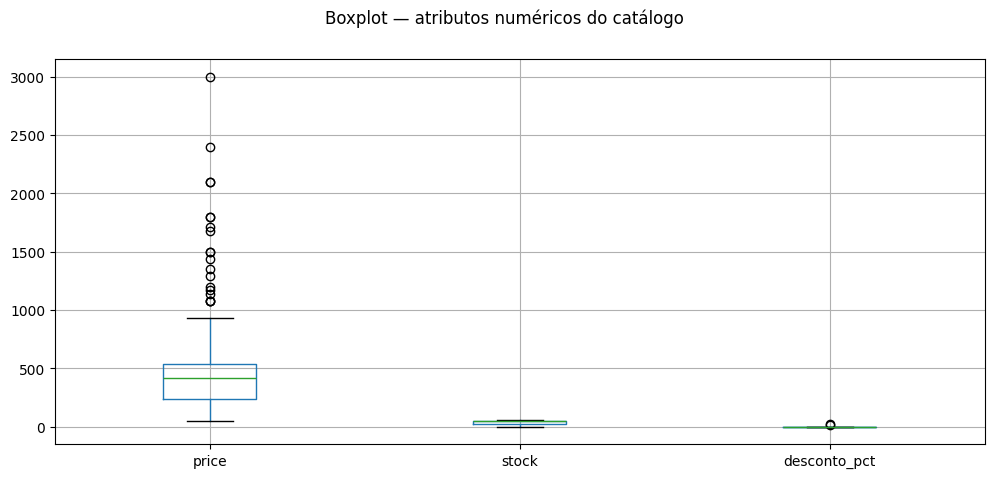

In [9]:
df.boxplot(column=['price', 'stock', 'desconto_pct'], figsize=(12, 5))
plt.suptitle('Boxplot — atributos numéricos do catálogo')
plt.show()

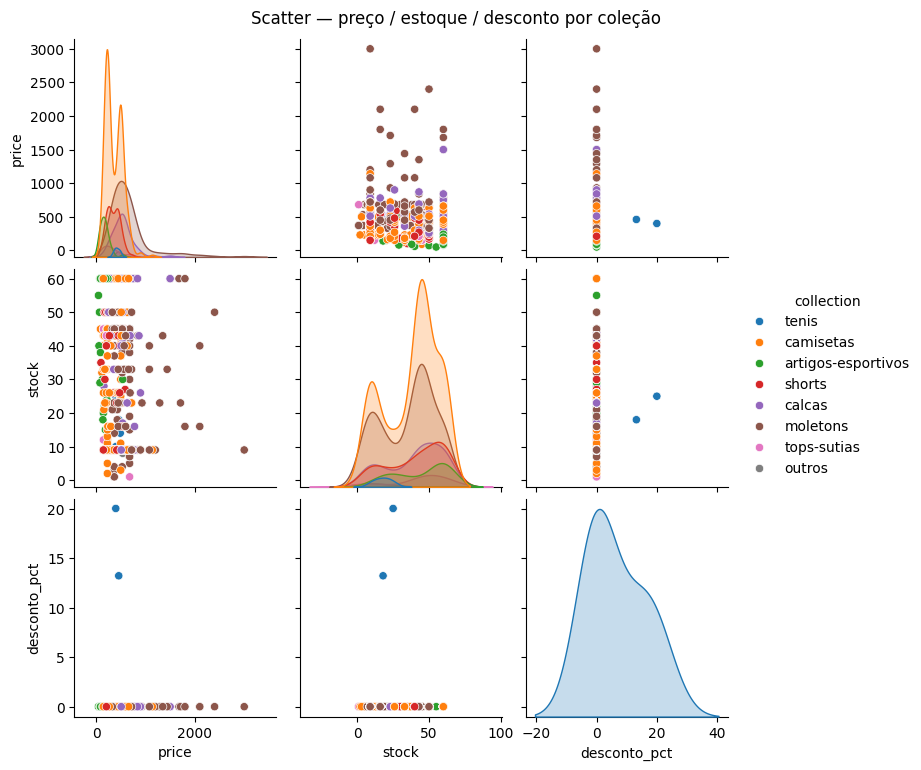

In [10]:
sns.pairplot(
    df,
    vars=['price', 'stock', 'desconto_pct'],
    hue=ALVO,
    height=2.5,
)
plt.suptitle('Scatter — preço / estoque / desconto por coleção', y=1.02)
plt.show()

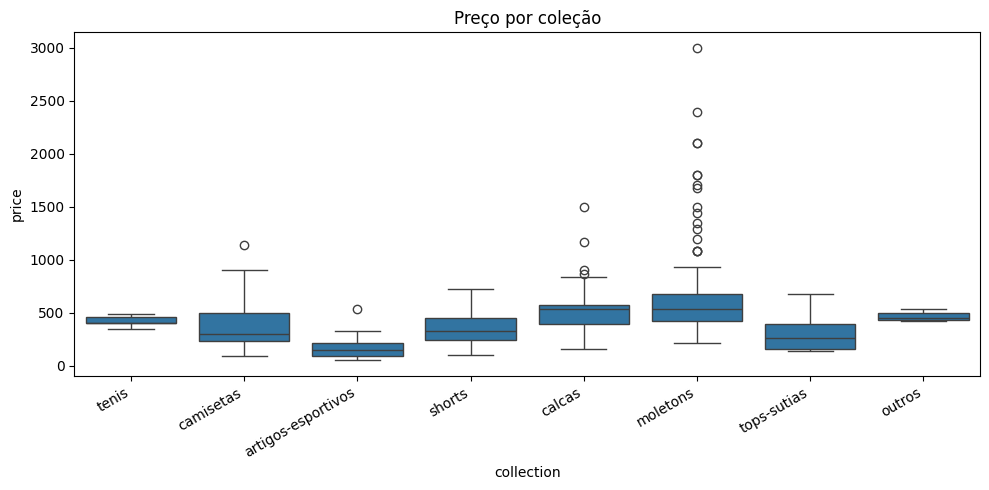

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=ALVO, y='price', data=df, whis=1.5)
plt.xticks(rotation=30, ha='right')
plt.title('Preço por coleção')
plt.tight_layout()
plt.show()

Amostras atuais: 546
Se remover outliers de price/stock: 527
(Mantendo a base completa no fluxo principal — produtos premium ficam no catálogo.)


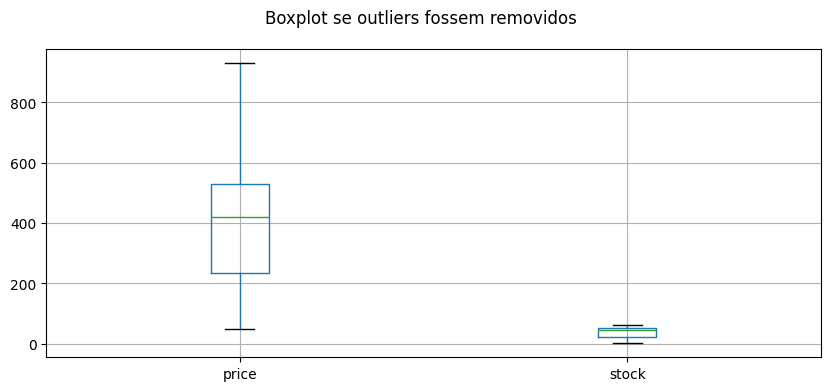

In [12]:
def remove_outliers(df: pd.DataFrame, cols=None) -> pd.DataFrame:
    '''Remove outliers com regra IQR (1,5 × IQR) nos atributos numéricos.'''
    cols = cols or ['price', 'stock']
    out = df.copy()
    for atributo in cols:
        q75, q25 = np.percentile(out[atributo].dropna().values, [75, 25])
        iqr = q75 - q25
        if iqr == 0:
            continue
        out = out[
            (out[atributo] <= (q75 + 1.5 * iqr)) &
            (out[atributo] >= (q25 - 1.5 * iqr))
        ]
    return out.reset_index(drop=True)

# Em catálogo, outliers de preço podem ser produtos premium legítimos.
# Por padrão só reportamos; descomente a linha abaixo para remover.
print(f'Amostras atuais: {len(df)}')
df_sem_outliers = remove_outliers(df)
print(f'Se remover outliers de price/stock: {len(df_sem_outliers)}')
print('(Mantendo a base completa no fluxo principal — produtos premium ficam no catálogo.)')

df_sem_outliers.boxplot(column=['price', 'stock'], figsize=(10, 4))
plt.suptitle('Boxplot se outliers fossem removidos')
plt.show()

## Pré-processamento: distribuição das classes (coleções)

collection
camisetas             224
moletons              149
shorts                 61
calcas                 60
artigos-esportivos     29
tops-sutias            15
tenis                   5
outros                  3
Name: count, dtype: int64

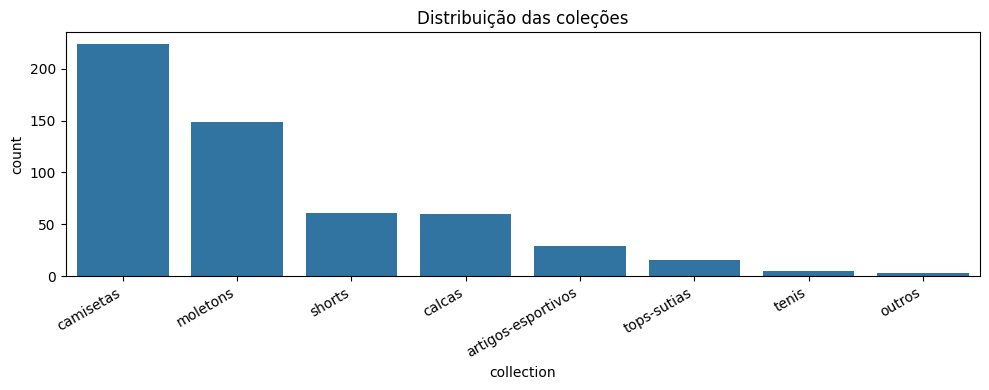


Esporte:


sport
Lifestyle     130
Futebol        99
Treino         69
Corrida        50
Basquete       43
Golfe          41
Outdoor        41
Tênis          29
Dança          14
Rugby          10
Geral           7
Skate           7
Musculação      3
Vôlei           1
Yoga            1
Name: count, dtype: int64


Marca:


brand
Nike         314
Adidas       171
Jordan        36
ArenaRun       6
IronGym        5
FlexFit        3
KickSport      2
GoalMax        2
JumpPro        2
NetPlay        2
HydroFit       1
CarryFit       1
SunSport       1
Name: count, dtype: int64

In [13]:
display(df[ALVO].value_counts())

plt.figure(figsize=(10, 4))
sns.countplot(x=ALVO, data=df, order=df[ALVO].value_counts().index)
plt.xticks(rotation=30, ha='right')
plt.title('Distribuição das coleções')
plt.tight_layout()
plt.show()

print('\nEsporte:')
display(df['sport'].value_counts().head(15))
print('\nMarca:')
display(df['brand'].value_counts())

## Pré-processamento: correlação entre atributos numéricos

,price,compareAt,stock,desconto_pct
price,1.000000,-0.003469,-0.132702,-0.004796
compareAt,-0.003469,1.000000,-0.054063,0.973368
stock,-0.132702,-0.054063,1.000000,-0.050374
desconto_pct,-0.004796,0.973368,-0.050374,1.000000


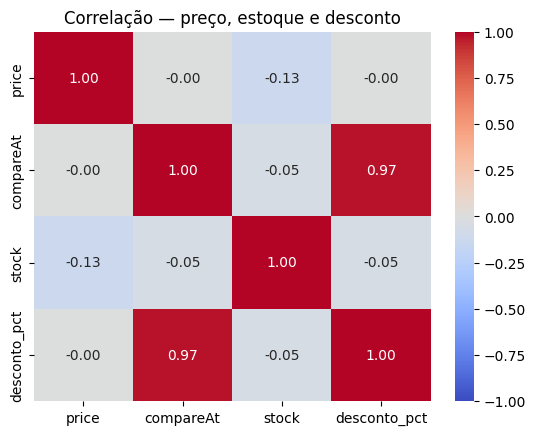

In [14]:
df_corr_src = df.copy()
df_corr_src['compareAt'] = df_corr_src['compareAt'].fillna(0)
df_correlation = df_corr_src[ATRIBUTOS_NUM].corr()
display(df_correlation)

sns.heatmap(
    df_correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
)
plt.title('Correlação — preço, estoque e desconto')
plt.show()

## Exportar base pré-processada (para o SportArena)

1. `products.json` — catálogo limpo para o seed (preços reais)  
2. `products_features.csv` — features normalizadas para recomendação / ML  
3. `parametros_preprocessamento.json` — μ e σ da normalização

In [15]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- 1) Catálogo para seed (schema Prisma) ---
CATEGORY_BY_COLLECTION = {
    'tenis': 'Calçados',
    'artigos-esportivos': 'Acessórios',
    'calcas': 'Camisetas',
    'shorts': 'Camisetas',
    'tops-sutias': 'Camisetas',
    'moletons': 'Camisetas',
    'camisetas': 'Camisetas',
    'outros': 'Camisetas',
}

catalogo = []
for _, row in df.iterrows():
    compare = row['compareAt']
    item = {
        'name': row['name'],
        'brand': row['brand'],
        'description': row['description'],
        'price': round(float(row['price']), 2),
        'compareAt': None if pd.isna(compare) else round(float(compare), 2),
        'size': row['size'] if row['size'] else None,
        'color': row['color'] if row['color'] else None,
        'sport': row['sport'] if row['sport'] else None,
        'stock': int(row['stock']),
        'imageUrl': row['imageUrl'] if row['imageUrl'] else None,
        'category': CATEGORY_BY_COLLECTION.get(row['collection'], row['category']),
        'active': bool(row['active']),
        'slug': row['slug'],
    }
    catalogo.append(item)

products_out = OUT_DIR / 'products.json'
products_out.write_text(
    json.dumps(catalogo, ensure_ascii=False, indent=2) + '\n',
    encoding='utf-8',
)

# --- 2) Features normalizadas (recomendação) ---
X_final = df_num[ATRIBUTOS_NUM].values.astype(float)
X_final_norm, mu_final, sigma_final = normalizar(X_final)

features = df[['slug', 'name', 'brand', 'sport', 'collection', 'genero', 'category']].copy()
for i, col in enumerate(ATRIBUTOS_NUM):
    features[f'{col}_norm'] = X_final_norm[:, i]

features_path = OUT_DIR / 'products_features.csv'
features.to_csv(features_path, index=False)

# --- 3) Parâmetros ---
params = {
    'atributos_numericos': ATRIBUTOS_NUM,
    'mu': mu_final.tolist(),
    'sigma': sigma_final.tolist(),
    'alvo': ALVO,
    'colecoes': sorted(df[ALVO].unique().tolist()),
    'total_produtos': len(catalogo),
    'fonte': str(PRODUCTS_PATH.as_posix()),
}
(OUT_DIR / 'parametros_preprocessamento.json').write_text(
    json.dumps(params, ensure_ascii=False, indent=2),
    encoding='utf-8',
)

print('Arquivos gerados:')
print(f'  - {products_out}')
print(f'  - {features_path}')
print(f'  - {OUT_DIR / "parametros_preprocessamento.json"}')
print(f'\nProdutos finais no catálogo: {len(catalogo)}')
display(features.head())

Arquivos gerados:
  - C:\SportArena\packages\database\prisma\data\products.json
  - C:\SportArena\packages\database\prisma\data\products_features.csv
  - C:\SportArena\packages\database\prisma\data\parametros_preprocessamento.json

Produtos finais no catálogo: 546


,slug,name,brand,sport,collection,genero,category,price_norm,compareAt_norm,stock_norm,desconto_pct_norm
0,tenis-running-pro-x,Tênis Running Pro X,ArenaRun,Corrida,tenis,nao_informado,Calçados,-0.160612,15.988725,-0.697796,19.455831
1,camisa-futebol-dry-fit,Camisa Futebol Dry-Fit,KickSport,Futebol,camisetas,nao_informado,Camisetas,-1.065182,-0.060553,0.107580,-0.059345
2,bola-oficial-campo,Bola Oficial Campo,GoalMax,Futebol,artigos-esportivos,nao_informado,Bolas,-0.864166,-0.060553,-1.234714,-0.059345
3,garrafa-termica-750ml,Garrafa Térmica 750ml,HydroFit,Geral,artigos-esportivos,nao_informado,Acessórios,-1.232695,-0.060553,1.181415,-0.059345
4,halteres-5kg-par,Halteres 5kg (par),IronGym,Musculação,artigos-esportivos,nao_informado,Equipamentos,-0.998177,-0.060553,-0.966255,-0.059345


## Resultados finais da pipeline

RESULTADOS DO PRÉ-PROCESSAMENTO — SportArena

1) Volume
   Produtos finais: 546
   Colunas do catálogo: 13
   Atributos numéricos (análise): ['price', 'compareAt', 'stock', 'desconto_pct']
   Alvo: collection

2) Distribuição por coleção (alvo)


,qtd,pct
collection,,
camisetas,224,41.0
moletons,149,27.3
shorts,61,11.2
calcas,60,11.0
artigos-esportivos,29,5.3
tops-sutias,15,2.7
tenis,5,0.9
outros,3,0.5



3) Distribuição por gênero


,qtd,pct
genero,,
masculino,330,60.4
infantil,84,15.4
feminino,74,13.6
unissex,33,6.0
nao_informado,25,4.6



4) Estatísticas de preço, estoque e desconto


,price,stock,desconto_pct
count,546.00,546.00,546.00
mean,447.84,38.00,0.06
std,298.48,18.62,1.03
min,49.90,1.00,0.00
25%,239.94,23.00,0.00
50%,419.94,45.00,0.00
75%,539.94,50.00,0.00
max,2999.94,60.00,20.00


... (6 outputs left out)


8) Qualidade dos dados
   Sem imageUrl: 0
   Com promoção (compareAt): 2 (0.4%)
   Slugs duplicados restantes: 0
   Valores ausentes totais: 544 (compareAt nulo = sem promoção)

9) Outliers (relatório)
   Produtos fora do IQR (price/stock): 19
   Mantidos no catálogo: 546 (premium não removido)

10) Correlação (numéricos)


,price,compareAt,stock,desconto_pct
price,1.000,-0.003,-0.133,-0.005
compareAt,-0.003,1.000,-0.054,0.973
stock,-0.133,-0.054,1.000,-0.050
desconto_pct,-0.005,0.973,-0.050,1.000



11) Arquivos exportados
   - C:\SportArena\packages\database\prisma\data\products.json
   - C:\SportArena\packages\database\prisma\data\products_features.csv
   - C:\SportArena\packages\database\prisma\data\parametros_preprocessamento.json
   Total no products.json: 546

12) Amostra do catálogo final


,name,brand,collection,genero,price,stock,sport,slug
0,Tênis Running Pro X,ArenaRun,tenis,nao_informado,399.9,25,Corrida,tenis-running-pro-x
1,Camisa Futebol Dry-Fit,KickSport,camisetas,nao_informado,129.9,40,Futebol,camisa-futebol-dry-fit
2,Bola Oficial Campo,GoalMax,artigos-esportivos,nao_informado,189.9,15,Futebol,bola-oficial-campo
3,Garrafa Térmica 750ml,HydroFit,artigos-esportivos,nao_informado,79.9,60,Geral,garrafa-termica-750ml
4,Halteres 5kg (par),IronGym,artigos-esportivos,nao_informado,149.9,20,Musculação,halteres-5kg-par
5,Shorts Training Flex,ArenaRun,shorts,nao_informado,99.9,35,Treino,shorts-training-flex
6,Tênis Trail Grip Max,ArenaRun,tenis,nao_informado,459.9,18,Corrida,tenis-trail-grip-max
7,Tênis Basketball Elevate,JumpPro,tenis,nao_informado,489.9,14,Basquete,tenis-basketball-elevate
8,Camisa Running Breath,ArenaRun,camisetas,nao_informado,119.9,32,Corrida,camisa-running-breath
9,Regata Training Core,IronGym,camisetas,nao_informado,89.9,45,Musculação,regata-training-core


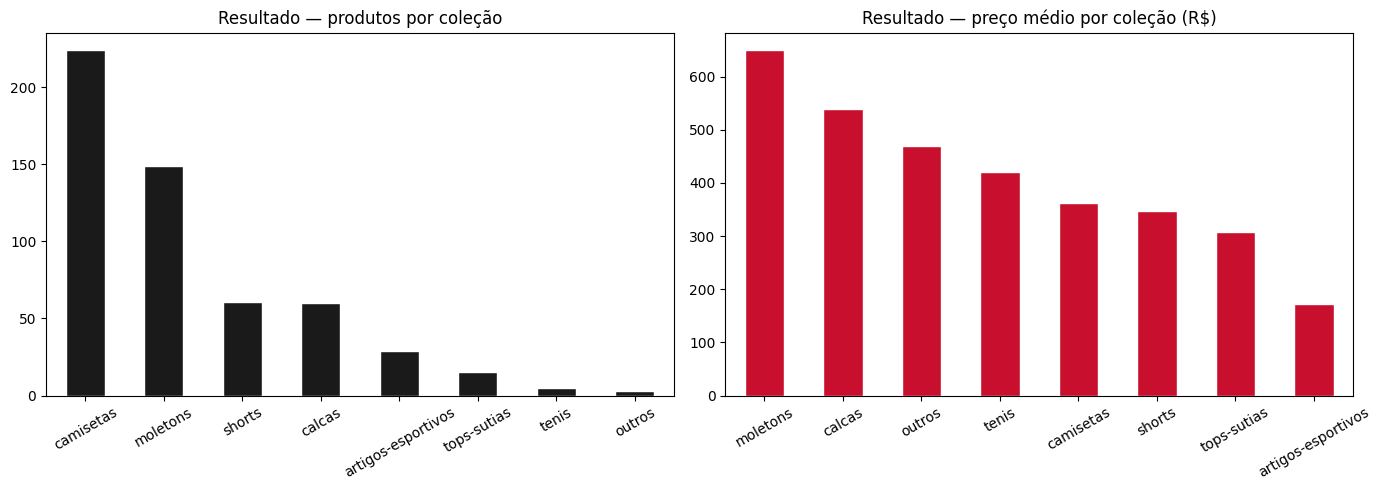


Pipeline concluída.


In [16]:
# --- Resultados finais ---

print('=' * 60)
print('RESULTADOS DO PRÉ-PROCESSAMENTO — SportArena')
print('=' * 60)

print(f'\n1) Volume')
print(f'   Produtos finais: {len(df)}')
print(f'   Colunas do catálogo: {len(CAMPOS_CATALOGO)}')
print(f'   Atributos numéricos (análise): {ATRIBUTOS_NUM}')
print(f'   Alvo: {ALVO}')

print(f'\n2) Distribuição por coleção (alvo)')
disp_colecao = (
    df[ALVO]
    .value_counts()
    .rename('qtd')
    .to_frame()
)
disp_colecao['pct'] = (disp_colecao['qtd'] / len(df) * 100).round(1)
display(disp_colecao)

print(f'\n3) Distribuição por gênero')
disp_genero = (
    df['genero']
    .value_counts()
    .rename('qtd')
    .to_frame()
)
disp_genero['pct'] = (disp_genero['qtd'] / len(df) * 100).round(1)
display(disp_genero)

print(f'\n4) Estatísticas de preço, estoque e desconto')
display(df[['price', 'stock', 'desconto_pct']].describe().round(2))

print(f'\n5) Preço médio / estoque médio por coleção')
por_colecao = (
    df.groupby(ALVO)
    .agg(
        qtd=('slug', 'count'),
        preco_medio=('price', 'mean'),
        preco_min=('price', 'min'),
        preco_max=('price', 'max'),
        estoque_medio=('stock', 'mean'),
        desconto_medio=('desconto_pct', 'mean'),
    )
    .round(2)
    .sort_values('qtd', ascending=False)
)
display(por_colecao)

print(f'\n6) Marcas')
display(df['brand'].value_counts().to_frame('qtd'))

print(f'\n7) Top esportes')
display(df['sport'].value_counts().head(10).to_frame('qtd'))

print(f'\n8) Qualidade dos dados')
sem_imagem = (df['imageUrl'].astype(str).str.len() == 0).sum()
com_promo = df['compareAt'].notna().sum()
duplicatas_slug = df.duplicated(subset=['slug']).sum()
print(f'   Sem imageUrl: {sem_imagem}')
print(f'   Com promoção (compareAt): {com_promo} ({com_promo / len(df) * 100:.1f}%)')
print(f'   Slugs duplicados restantes: {duplicatas_slug}')
print(f'   Valores ausentes totais: {int(df.isna().sum().sum())} (compareAt nulo = sem promoção)')

print(f'\n9) Outliers (relatório)')
n_out = len(df) - len(df_sem_outliers)
print(f'   Produtos fora do IQR (price/stock): {n_out}')
print(f'   Mantidos no catálogo: {len(df)} (premium não removido)')

print(f'\n10) Correlação (numéricos)')
display(df_correlation.round(3))

print(f'\n11) Arquivos exportados')
print(f'   - {products_out}')
print(f'   - {features_path}')
print(f'   - {OUT_DIR / "parametros_preprocessamento.json"}')
print(f'   Total no products.json: {len(catalogo)}')

print(f'\n12) Amostra do catálogo final')
display(
    df[['name', 'brand', 'collection', 'genero', 'price', 'stock', 'sport', 'slug']]
    .head(15)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df[ALVO].value_counts().plot(
    kind='bar', ax=axes[0], color='#1a1a1a', edgecolor='white'
)
axes[0].set_title('Resultado — produtos por coleção')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=30)

df.groupby(ALVO)['price'].mean().sort_values(ascending=False).plot(
    kind='bar', ax=axes[1], color='#c8102e', edgecolor='white'
)
axes[1].set_title('Resultado — preço médio por coleção (R$)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print('\n' + '=' * 60)
print('Pipeline concluída.')
print('=' * 60)

## Próximo passo no projeto

```bash
npm run db:seed
```

O seed lê `packages/database/prisma/data/products.json` e atualiza o PostgreSQL.  
As features em `products_features.csv` podem alimentar um modelo de
recomendação (similaridade por esporte/coleção/preço) no futuro.